# 01 · Probabilidad y simulación

**Objetivo:** usar simulación para responder la pregunta que más importa en la práctica:
*¿cuándo es “n grande” suficiente para que la aproximación normal funcione?*

Spoiler: depende de la distribución. Con métricas de negocio típicas (la mayoría en cero,
unos pocos valores enormes) la respuesta puede ser “miles”.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_stats import mean_ci

## 1. Tres poblaciones

- **Normal**: el caso de libro.
- **Exponencial**: asimetría moderada (tiempos de espera).
- **Gasto cero-inflado**: 2 % compra; quien compra gasta según una lognormal.
  Es la forma de “ingreso por usuario” en casi cualquier producto digital.

In [2]:
def normal(size):
    return rng.normal(10, 3, size)


def exponential(size):
    return rng.exponential(10, size)


def zero_inflated(size):
    buys = rng.random(size) < 0.02
    return np.where(buys, rng.lognormal(4, 1, size), 0.0)


POPULATIONS = {"normal": normal, "exponencial": exponential, "cero-inflada": zero_inflated}
TRUE_MEAN = {"normal": 10.0, "exponencial": 10.0, "cero-inflada": 0.02 * np.exp(4 + 0.5)}

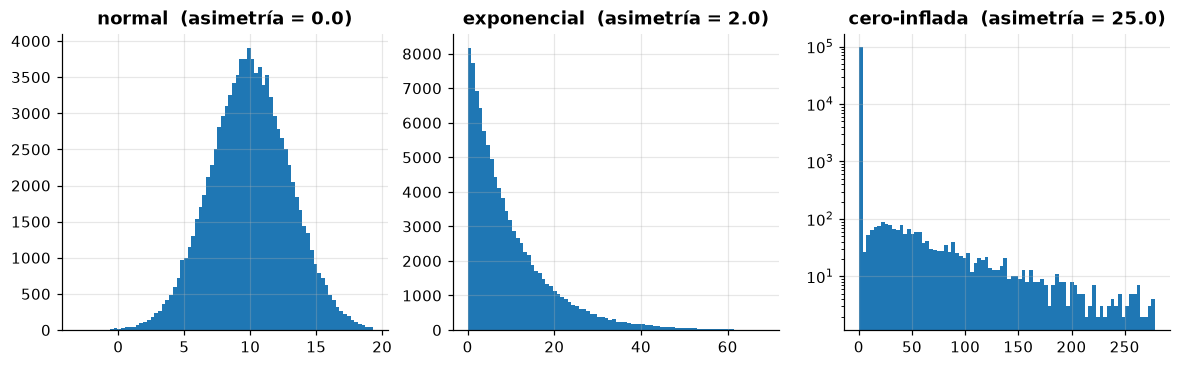

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, (name, sampler) in zip(axes, POPULATIONS.items(), strict=True):
    x = sampler(100_000)
    ax.hist(x[x < np.quantile(x, 0.999)], bins=80, color="C0")
    ax.set_title(f"{name}  (asimetría = {stats.skew(x):.1f})")
    ax.set_yscale("log" if name == "cero-inflada" else "linear")

## 2. Ley de grandes números

$\bar X_n \to \mu$ casi seguramente. La *velocidad* es $\sigma/\sqrt n$, y en la cero-inflada
$\sigma/\mu$ es enorme: la media corrida tarda mucho en estabilizarse y salta con cada compra grande.

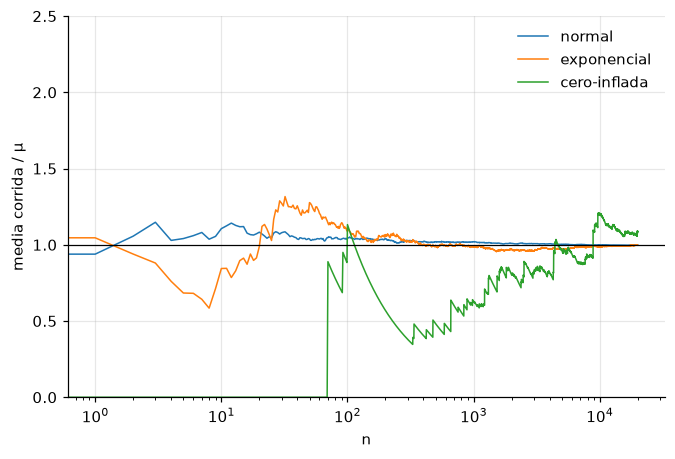

In [4]:
n = 20_000
fig, ax = plt.subplots()
for name, sampler in POPULATIONS.items():
    x = sampler(n)
    ax.plot(np.cumsum(x) / np.arange(1, n + 1) / TRUE_MEAN[name], label=name, lw=1)
ax.axhline(1, color="k", lw=0.8)
ax.set_xscale("log")
ax.set_ylim(0, 2.5)
ax.set_xlabel("n")
ax.set_ylabel("media corrida / μ")
ax.legend();

## 3. Teorema central del límite

La asimetría de $\bar X_n$ decae como $\gamma_1/\sqrt n$: si la población tiene asimetría 20,
hace falta $n \approx 40\,000$ para que la media muestral tenga asimetría 0.1.

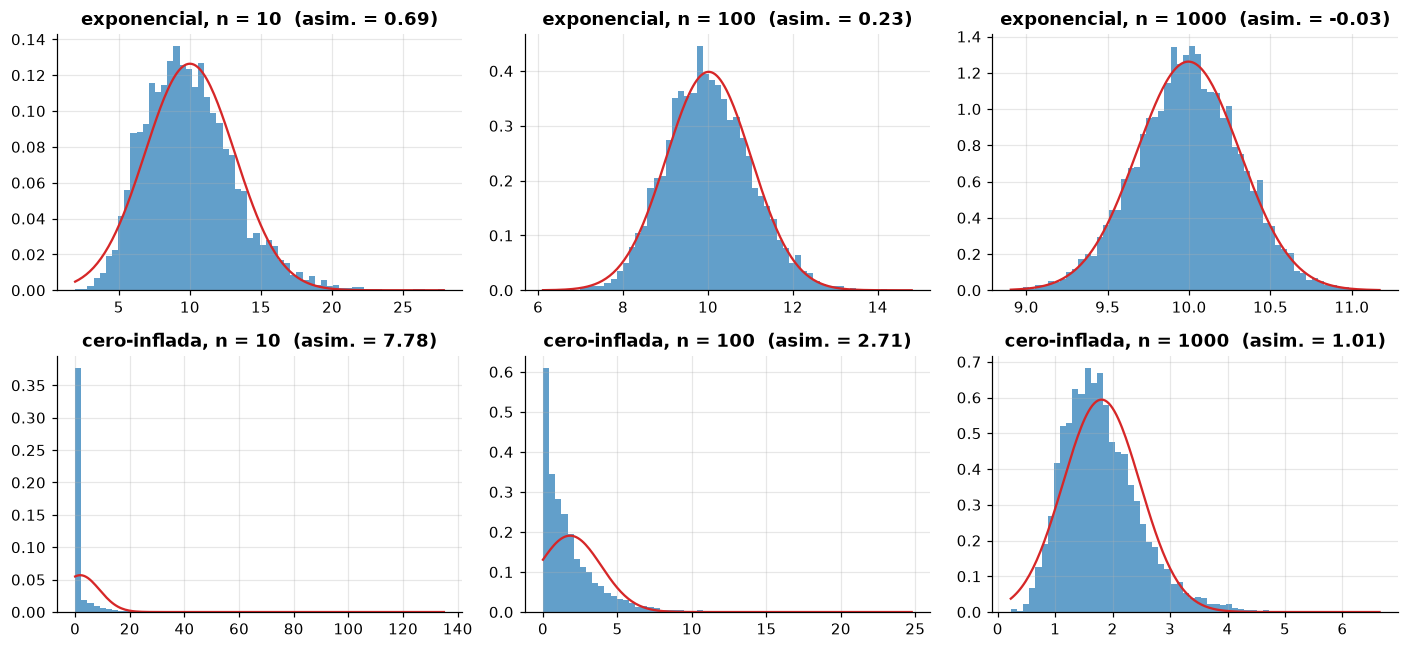

In [5]:
ns = [10, 100, 1000]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for row, name in enumerate(["exponencial", "cero-inflada"]):
    for col, n in enumerate(ns):
        means = POPULATIONS[name]((5000, n)).mean(axis=1)
        ax = axes[row, col]
        ax.hist(means, bins=60, density=True, color="C0", alpha=0.7)
        g = np.linspace(means.min(), means.max(), 200)
        ax.plot(g, stats.norm.pdf(g, means.mean(), means.std()), "C3")
        ax.set_title(f"{name}, n = {n}  (asim. = {stats.skew(means):.2f})")
fig.tight_layout()

## 4. Cobertura de intervalos

Un intervalo del 95 % debe contener a $\mu$ en el 95 % de las repeticiones. Lo medimos.
Primero el intervalo de `applied_stats` sobre una muestra; luego la simulación, vectorizada.

In [6]:
x = exponential(50)
print("IC 95 % (applied_stats):", np.round(mean_ci(x), 3), "| μ = 10")

IC 95 % (applied_stats): [ 7.077 12.881] | μ = 10


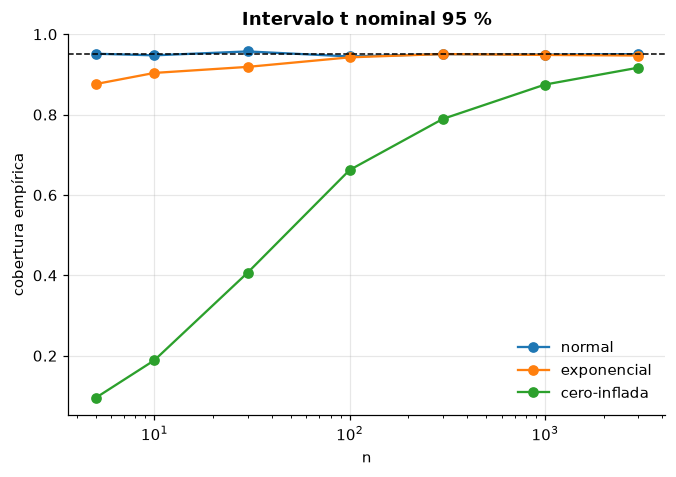

In [7]:
def t_coverage(sampler, mu, n, reps=4000, conf=0.95):
    x = sampler((reps, n))
    m, se = x.mean(axis=1), x.std(axis=1, ddof=1) / np.sqrt(n)
    t = stats.t.ppf((1 + conf) / 2, n - 1)
    return np.mean((m - t * se <= mu) & (mu <= m + t * se))


ns = [5, 10, 30, 100, 300, 1000, 3000]
fig, ax = plt.subplots()
for name, sampler in POPULATIONS.items():
    cov = [t_coverage(sampler, TRUE_MEAN[name], n) for n in ns]
    ax.plot(ns, cov, "o-", label=name)
ax.axhline(0.95, color="k", ls="--", lw=1)
ax.set_xscale("log")
ax.set_xlabel("n")
ax.set_ylabel("cobertura empírica")
ax.set_title("Intervalo t nominal 95 %")
ax.legend();

## Para llevar

- La regla “n ≥ 30” es para distribuciones casi simétricas; no aplica a métricas de ingreso.
- Antes de confiar en un intervalo, **simular su cobertura** con una población parecida a los datos.
- En métricas cero-infladas, la incertidumbre la domina la fracción que convierte, no el total de usuarios.